In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, MPIBackend, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
 
# import pandas as pd
from scipy import signal

from matplotlib.gridspec import GridSpec
import os
import os.path as op
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 'truetype'

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/suzuki_larkum_experiments'
os.makedirs(pathfig, exist_ok=True)
import matplotlib
from cmcrameri import cm

step_cm = int(len(cm.lipari.colors) / 7)
cm_time = cm.lipari.colors[len(cm.lipari.colors)-20: 0 : -int(step_cm/1.1)]
cm_time_map = matplotlib.colors.ListedColormap(cm_time)

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
import sys
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color

n_procs = 10

In [2]:
window_len, scaling_factor = 30, 1

net = duecker_ET_model(mesh_shape=(1,1))
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3
t0 = 20

for i in range(1):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='none')
smooth_dpl = dpl[0].copy()
smooth_dpl.smooth(window_len).scale(scaling_factor)


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


In [3]:
timevec = net.cell_response.times


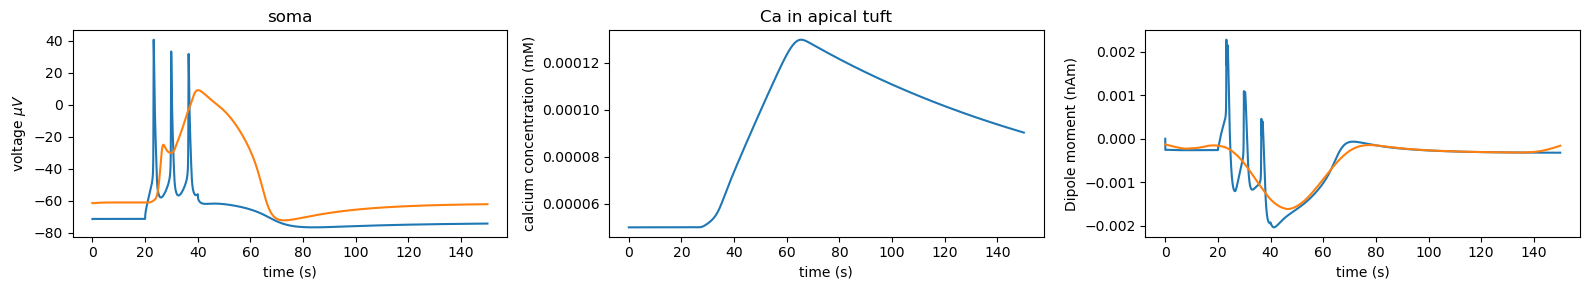

In [4]:
timevec = net.cell_response.times

gid = 3
fig, axs = plt.subplots(1,3,figsize=(16,3))
# v_int2 = net.cell_response.vsec[0][0]['soma']
# plt.plot(timevec, v_int2)
# v_l2 = net.cell_response.vsec[0][35]['soma']
# plt.plot(timevec, v_l2)
# v_int5 = net.cell_response.vsec[0][135]['soma']
# plt.plot(timevec, v_int5)
v_l5 = net.cell_response.vsec[0][gid]['soma']
v_l5_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
axs[0].plot(timevec, v_l5)
axs[0].plot(timevec, v_l5_apcl)

axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')

ca_l5 = net.cell_response.ca[0][gid]['apical_tuft']

axs[1].plot(timevec, ca_l5)
axs[1].set_title('Ca in apical tuft')
axs[1].set_ylabel('calcium concentration (mM)')

axs[2].plot(timevec, dpl[0].data['L5'], label='unsmoothed')
axs[2].plot(timevec, smooth_dpl.data['L5'], label='smoothed')

axs[2].set_title('')
axs[2].set_ylabel('Dipole moment (nAm)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
#fig.savefig(os.path.join(pathfig,'l5_electrophysio.png'))

In [5]:
len(depths)

20

In [6]:
window_len, scaling_factor = 15, 1000

net = duecker_ET_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-50,2050,100)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3
t0 = 20

net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+20)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


In [7]:
from hnn_core.extracellular import _get_laminar_z_coords


contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

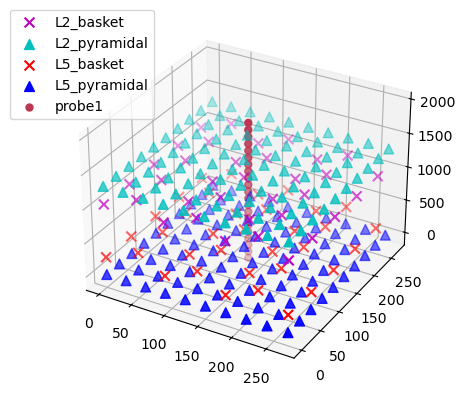

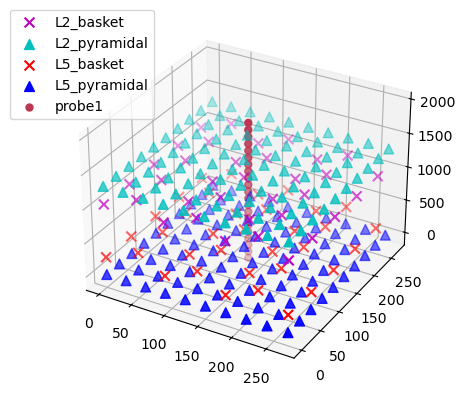

In [8]:
net.plot_cells()

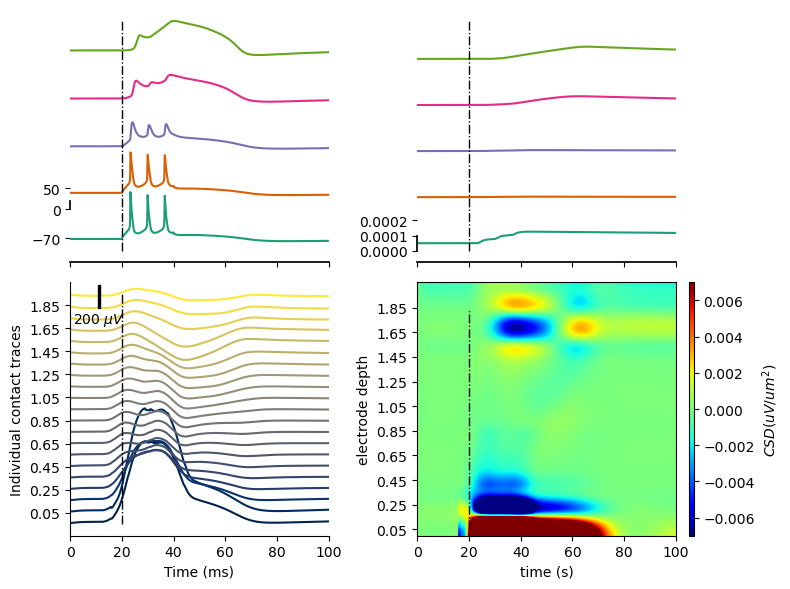

In [9]:
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255

fig, axs = plt.subplots(2,2, figsize=(8,6), sharex=True)

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"]['cell_object'].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    # axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    # axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[0,0].plot(timevec, v + i*110, color=cols[i])
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[0,1].plot(timevec, ca + i*0.0003, color=cols[i])
    prevL += L[i]


axs[0,0].set_yticks([-70, 0, 50])
axs[0,0].spines['left'].set_bounds(-85, -35)
axs[0,0].spines['left'].set_bounds(0, 20)
axs[0,1].spines['left'].set_bounds(0, 20)
axs[0,1].spines['left'].set_bounds(0, 0.0001)
axs[0,1].set_yticks([0, 0.0001, 0.0002])
axs[0,1].spines['bottom'].set_linewidth(1.25)
axs[0,1].spines['left'].set_linewidth(1.25)
axs[0,0].spines['bottom'].set_linewidth(1.25)
axs[0,0].spines['left'].set_linewidth(1.25)

axs[0,0].spines['top'].set_visible(False)
axs[0,0].spines['right'].set_visible(False)
axs[0,0].plot(np.ones((100,))*20, np.linspace(-100, 450, 100), linewidth=1, color='k', linestyle='-.')
axs[0,1].plot(np.ones((100,))*20, np.linspace(-0, 0.0015, 100), linewidth=1, color='k', linestyle='-.')

axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)


new_lim = contact_labels[1:len(contact_labels)-1:2]/1000

net.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,0], show=False, voltage_offset=100)
lfp_ticks = axs[1,0].get_yticks()

axs[1,0].set_yticks(np.linspace(lfp_ticks[1], lfp_ticks[-2], len(new_lim)))
axs[1,0].set_yticklabels(new_lim)
# axs[1,1].set_ylim((lfp_ticks[0], lfp_ticks[-1]+100))
axs[1,1].set_xlabel('time (s)')

net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,1], show=False, vmin=-0.007, vmax=0.007)
csd_ticks = axs[1,1].get_yticks()
axs[1,1].set_yticks(np.linspace(csd_ticks[1], csd_ticks[-2], len(new_lim)))
axs[1,1].set_yticklabels(new_lim)


axs[1,0].plot(np.ones((100,))*20, np.linspace(lfp_ticks[0], lfp_ticks[-1], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].plot(np.ones((100,))*20, np.linspace(csd_ticks[1], csd_ticks[-2], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].set_xlim((0, 100))
axs[1,0].spines['top'].set_visible(False)
axs[1,0].spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_unconnected.png'))
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_unconnected.pdf'), dpi=300)

## Note: source is the return current of the sink! (Rimehaug 2024, Einevoll book!)

In [7]:
def net_block_ca(net_no_ca):
    # block Ca
    # 
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
    net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0

    return net_no_ca

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


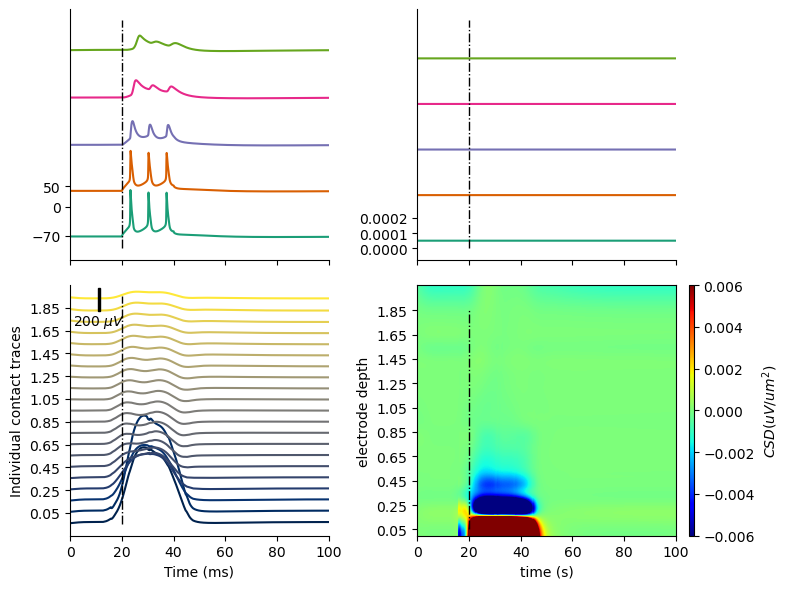

In [11]:
net_no_ca = duecker_ET_model()
net_no_ca.clear_connectivity()

net_no_ca = net_block_ca(net_no_ca)


net_no_ca.set_cell_positions(inplane_distance=30.)

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(1):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')

dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


fig, axs = plt.subplots(2,2, figsize=(8,6), sharex=True)

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net_no_ca.cell_types["L5_pyramidal"]['cell_object'].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    # axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    # axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net_no_ca.cell_response.vsec[0][171][section])
    axs[0,0].plot(timevec, v + i*110, color=cols[i])
    ca = np.array(net_no_ca.cell_response.ca[0][171][section])
    axs[0,1].plot(timevec, ca + i*0.0003, color=cols[i])
    prevL += L[i]


axs[0,0].set_yticks([-70, 0, 50])
axs[0,1].set_yticks([0, 0.0001, 0.0002])

axs[0,0].spines['top'].set_visible(False)
axs[0,0].spines['right'].set_visible(False)
axs[0,0].plot(np.ones((100,))*20, np.linspace(-100, 450, 100), linewidth=1, color='k', linestyle='-.')
axs[0,1].plot(np.ones((100,))*20, np.linspace(-0, 0.0015, 100), linewidth=1, color='k', linestyle='-.')

axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)


new_lim = contact_labels[1:len(contact_labels)-1:2]/1000

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,0], show=False, voltage_offset=100)
lfp_ticks = axs[1,0].get_yticks()

axs[1,0].set_yticks(np.linspace(lfp_ticks[1], lfp_ticks[-2], len(new_lim)))
axs[1,0].set_yticklabels(new_lim)
# axs[1,1].set_ylim((lfp_ticks[0], lfp_ticks[-1]+100))
axs[1,1].set_xlabel('time (s)')

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,1], show=False, vmin=-0.006, vmax=0.006)
csd_ticks = axs[1,1].get_yticks()
axs[1,1].set_yticks(np.linspace(csd_ticks[1], csd_ticks[-2], len(new_lim)))
axs[1,1].set_yticklabels(new_lim)


axs[1,0].plot(np.ones((100,))*20, np.linspace(lfp_ticks[0], lfp_ticks[-1], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].plot(np.ones((100,))*20, np.linspace(csd_ticks[1], csd_ticks[-2], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].set_xlim((0, 100))
axs[1,0].spines['top'].set_visible(False)
axs[1,0].spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_unconnected_block_ca.png'))
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_unconnected_block_ca.pdf'))



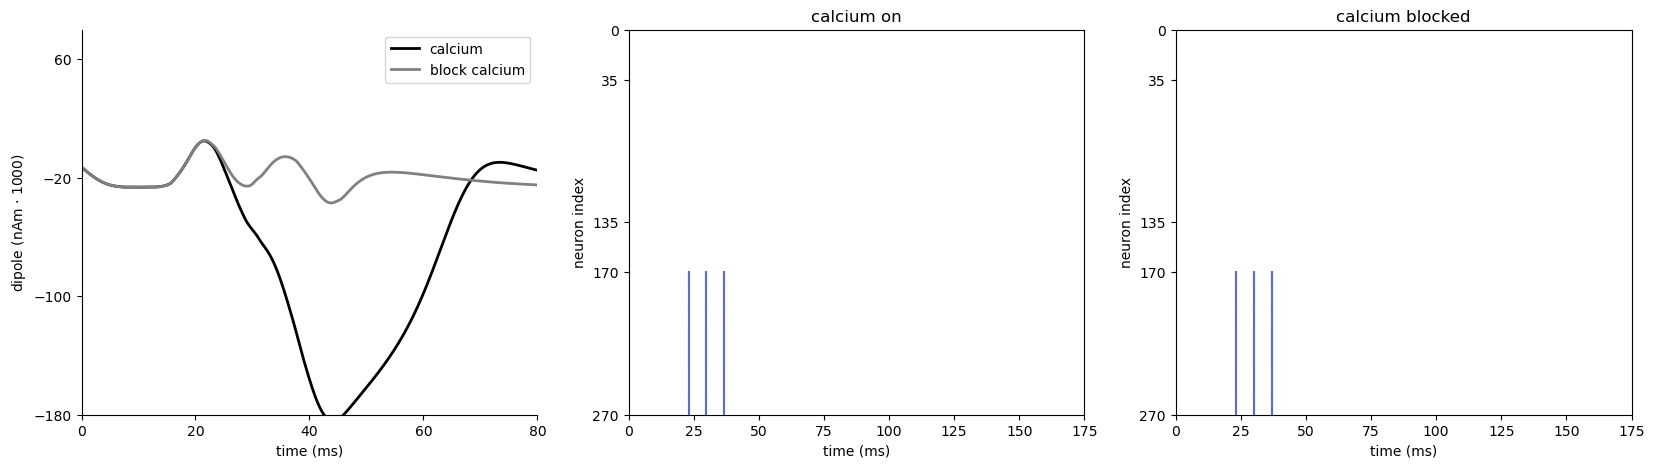

In [12]:
fig, ax = plt.subplots(1,3, figsize=(20,5))
ax[0].plot(timevec, dpl[0].data['L5'], color='k', label='calcium', linewidth=2)
ax[0].plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium', linewidth=2)

ax[0].set_ylabel('dipole (nAm $\cdot$ {scaling_factor})'.format(scaling_factor=scaling_factor))
ax[0].set_xlabel('time (ms)')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_xlim((0, 80))
ax[0].set_xticks(np.arange(0, 81, 20))
ax[0].set_ylim((-150, 80))
ax[0].set_yticks(np.arange(-180, 91, 80))


I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net, gid) for gid in gids]
ax[1].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[1].set_ylabel('neuron index')
ax[1].set_xlim([0, 175])
ax[1].set_xlabel('time (ms)')
ax[1].set_ylim([0, 270])
ax[1].set_yticks([0, 35, 135, 170, 270])
ax[1].invert_yaxis()
ax[1].set_xticks(np.arange(0, 176, 25))
ax[1].set_xlim((0, 175))

I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]
ax[2].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[2].set_ylabel('neuron index')
ax[2].set_xlim([0, 175])
ax[2].set_xlabel('time (ms)')
ax[2].set_ylim([0, 270])
ax[2].set_yticks([0, 35, 135, 170, 270])
ax[2].invert_yaxis()
ax[2].set_xticks(np.arange(0, 176, 25))
ax[2].set_xlim((0, 175))

ax[1].set_title('calcium on')
ax[2].set_title('calcium blocked')

ax[0].legend()
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_unconn.png'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_unconn.pdf'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_unconn.svg'))



In [13]:
window_len, scaling_factor = 15, 1000

net = duecker_ET_model()
net.connectivity[6]['nc_dict']['A_weight'] = 0

depths = list(list(range(-50,2050,100)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3
t0 = 20

net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+20)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)

net_no_ca = duecker_ET_model()
net_no_ca.connectivity[6]['nc_dict']['A_weight'] = 0
net_no_ca = net_block_ca(net_no_ca)


net_no_ca.set_cell_positions(inplane_distance=30.)

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(1):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')

dpl_no_ca[0].smooth(window_len).scale(scaling_factor)




Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


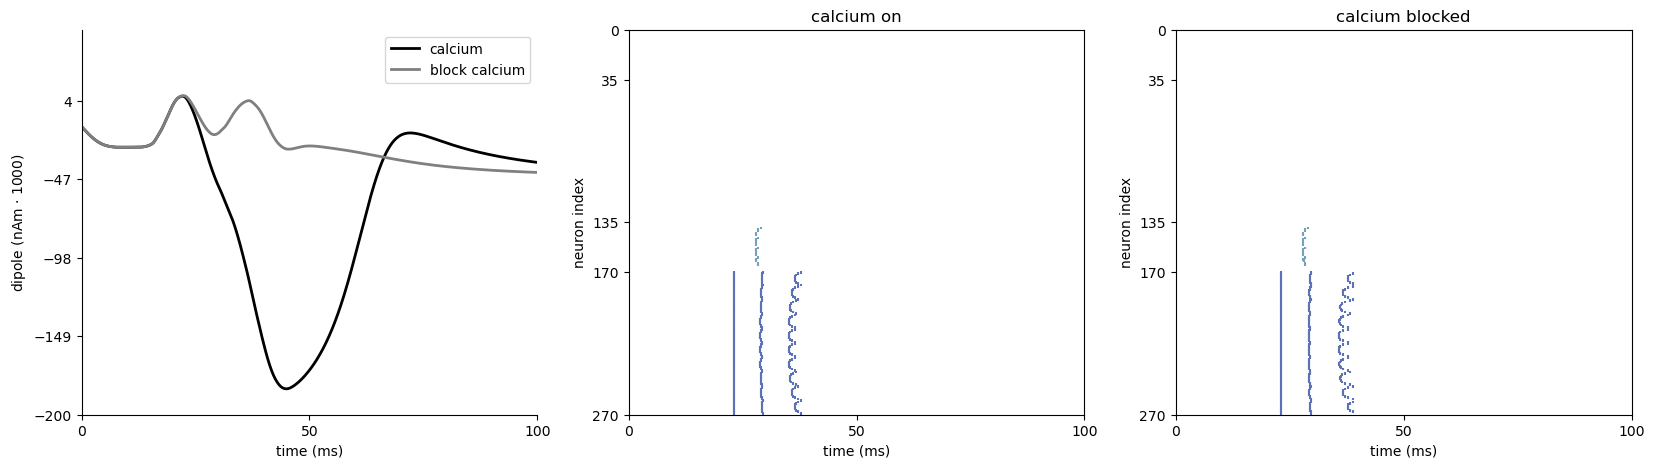

In [14]:
fig, ax = plt.subplots(1,3, figsize=(20,5), sharex=True)
ax[0].plot(timevec, dpl[0].data['L5'], color='k', label='calcium', linewidth=2)
ax[0].plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium', linewidth=2)

ax[0].set_ylabel('dipole (nAm $\cdot$ {scaling_factor})'.format(scaling_factor=scaling_factor))
ax[0].set_xlabel('time (ms)')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_xlim((0, 100))
ax[0].set_xticks(np.arange(0, 101, 50))
ax[0].set_ylim((-200, 50))
ax[0].set_yticks(np.arange(-200, 51, 51))


I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net, gid) for gid in gids]
ax[1].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[1].set_ylabel('neuron index')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylim([0, 270])
ax[1].set_yticks([0, 35, 135, 170, 270])
ax[1].invert_yaxis()

I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]
ax[2].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[2].set_ylabel('neuron index')
ax[2].set_xlabel('time (ms)')
ax[2].set_ylim([0, 270])
ax[2].set_yticks([0, 35, 135, 170, 270])
ax[2].invert_yaxis()

ax[1].set_title('calcium on')
ax[2].set_title('calcium blocked')

ax[0].legend()
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_inhibitionoff.png'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_inhibitionoff.pdf'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_unconn.svg'))

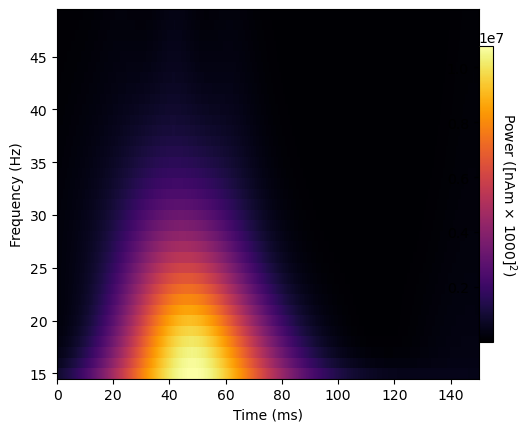

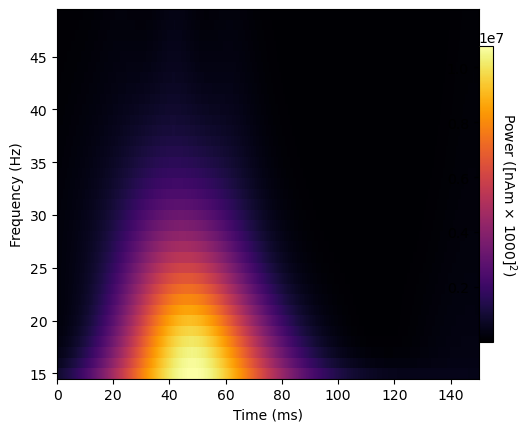

In [15]:
fig, ax = plt.subplots()
freqs = np.arange(15, 50, 1)
dpl[0].plot_tfr_morlet(freqs, n_cycles=3, tmin=0, ax=ax)


## Connected network

In [2]:
from hnn_core.extracellular import _get_laminar_z_coords




In [3]:
window_len, scaling_factor = 10, 1000

net = duecker_ET_model()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)

ampl = 3.5
t0 = 20

net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse',amplitude=ampl,t0=t0,tstop=t0+20)
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)
timevec = net.cell_response.times
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255



MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

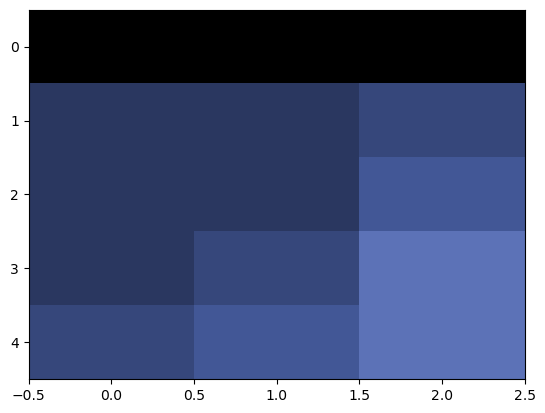

In [4]:
l5_cols_tone = ['k','#2A3760','#36477B','#425796', '#5C72B7']
l5_cols_tone_rgb = np.array([[0,0,0], [42, 55, 96],[54, 71, 123],[66, 87, 150],[92, 114, 183]])/255
l5cmap = matplotlib.colors.ListedColormap(l5_cols_tone_rgb)
im = plt.imshow(l5cmap.colors, aspect='auto', cmap=l5cmap)

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_17879/252865466.py:27: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 800x800 with 5 Axes> which fig.colorbar is called on.
  cb1 = plt.colorbar(im, ax=axs[0,0],orientation='horizontal',shrink=0.75)
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_17879/252865466.py:28: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 800x800 with 6 Axes> which fig.colorbar is called on.
  cb2 = plt.colorbar(im, ax=axs[0,1],orientation='horizontal',shrink=0.75)


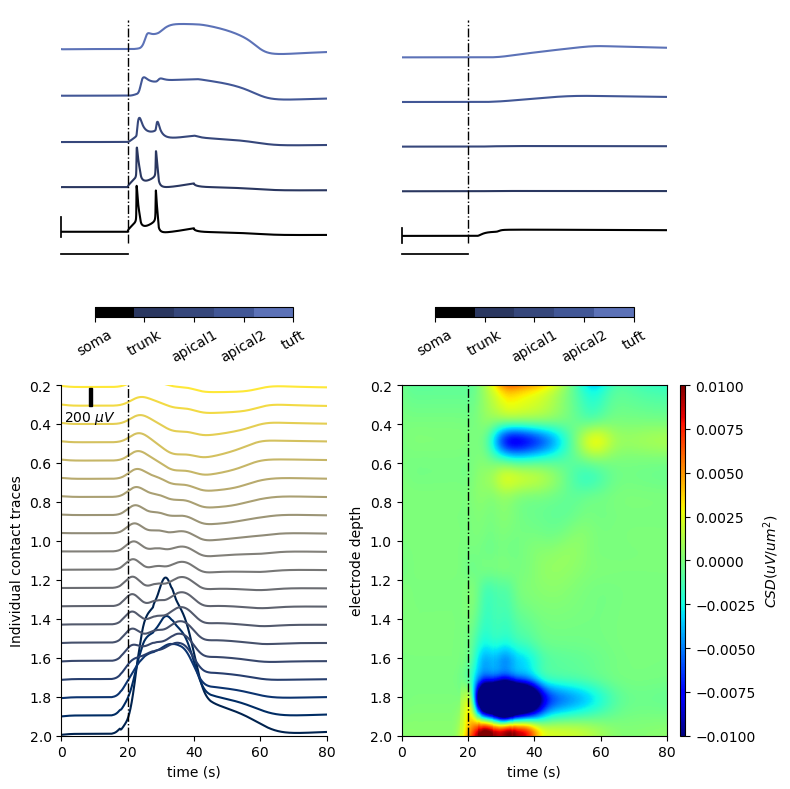

In [5]:
fig, axs = plt.subplots(2,2, figsize=(8,8))


sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"]['cell_object'].sections[section].L)

prevL = 0


# find neuron that spikes the most
l5_gids = np.array(net.cell_response.spike_gids[0])[np.array(net.cell_response.spike_gids[0]) > 170]
l5_spikes, counts = np.unique(l5_gids, return_counts=True)
gid_oi = int(l5_spikes[np.argmax(counts)])

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

for i, section in enumerate(sections):

    v = np.array(net.cell_response.vsec[0][gid_oi][section])
    axs[0,0].plot(timevec, v + i*110, color=l5_cols_tone[i])
    ca = np.array(net.cell_response.ca[0][gid_oi][section])
    axs[0,1].plot(timevec, ca + i*0.0003, color=l5_cols_tone[i])
    prevL += L[i]

cb1 = plt.colorbar(im, ax=axs[0,0],orientation='horizontal',shrink=0.75)
cb2 = plt.colorbar(im, ax=axs[0,1],orientation='horizontal',shrink=0.75)
cb1.ax.set_xticks(np.linspace(0.,np.max(l5cmap.colors),5))
cb2.ax.set_xticks(np.linspace(0.,np.max(l5cmap.colors),5))
cb1.ax.set_xticklabels(['soma','trunk','apical1','apical2','tuft'], rotation=30)
cb2.ax.set_xticklabels(['soma','trunk','apical1','apical2','tuft'], rotation=30)

axs[0,0].spines['top'].set_visible(False)
axs[0,0].spines['right'].set_visible(False)
axs[0,0].plot(np.ones((100,))*20, np.linspace(-100, 450, 100), linewidth=1, color='k', linestyle='-.')
axs[0,1].plot(np.ones((100,))*20, np.linspace(-0, 0.0015, 100), linewidth=1, color='k', linestyle='-.')

axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)


new_lim = np.abs(np.round(contact_labels[::2]/1000-2,1))

net.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,0], show=False, voltage_offset=200)
lfp_ticks = axs[1,0].get_yticks()

axs[1,0].set_ylim((lfp_ticks[0], lfp_ticks[-1]))
axs[1,0].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
axs[1,0].set_yticklabels(new_lim)
axs[1,0].set_xlabel('time (s)')

net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,1], show=False, vmin=-0.01, vmax=0.01)
axs[1,1].set_yticks(np.linspace(contact_labels[0], contact_labels[-1], len(new_lim)))
axs[1,1].set_yticklabels(new_lim)

axs[1,0].plot(np.ones((100,))*20, np.linspace(lfp_ticks[0], lfp_ticks[-1], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].plot(np.ones((100,))*20, np.linspace(contact_labels[0], contact_labels[-1], 100), linewidth=1, color='k', linestyle='-.')

axs[1,0].spines['top'].set_visible(False)
axs[1,0].spines['right'].set_visible(False)

axs[1,0].set_xlim((0, 80))
axs[1,1].set_xlim((0, 80))
axs[0,0].set_xlim((0, 80))
axs[0,1].set_xlim((0, 80))


axs[0,0].spines['left'].set_bounds(-85, -35)
axs[0,0].spines['bottom'].set_bounds(0, 20)
axs[0,1].spines['bottom'].set_bounds(0, 20)
axs[0,0].set_xticks([])
axs[0,1].set_xticks([])
axs[0,0].set_yticks([])
axs[0,1].set_yticks([])
axs[0,1].spines['left'].set_bounds(0, 0.0001)
axs[0,1].spines['bottom'].set_linewidth(1.25)
axs[0,1].spines['left'].set_linewidth(1.25)
axs[0,0].spines['bottom'].set_linewidth(1.25)
axs[0,0].spines['left'].set_linewidth(1.25)
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected.png'), dpi=300)
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected.svg'), dpi=300)
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected.pdf'), dpi=300)

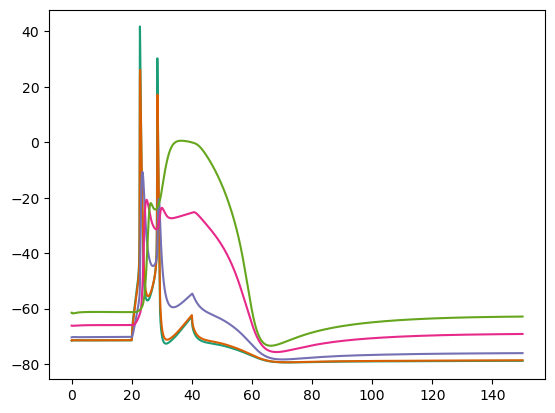

In [20]:
for i, section in enumerate(sections):
    # axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    # axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][gid_oi][section])
    plt.plot(timevec, v, color=cols[i])

    prevL += L[i]

In [8]:
net_no_ca = duecker_ET_model()

net_no_ca = net_block_ca(net_no_ca)


net_no_ca.set_cell_positions(inplane_distance=30.)

depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 20

for i in range(1):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')

dpl_no_ca[0].smooth(window_len).scale(scaling_factor)

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_17879/1521681605.py:26: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 800x800 with 5 Axes> which fig.colorbar is called on.
  cb1 = plt.colorbar(im, ax=axs[0,0],orientation='horizontal',shrink=0.75)
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_17879/1521681605.py:27: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 800x800 with 6 Axes> which fig.colorbar is called on.
  cb2 = plt.colorbar(im, ax=axs[0,1],orientation='horizontal',shrink=0.75)


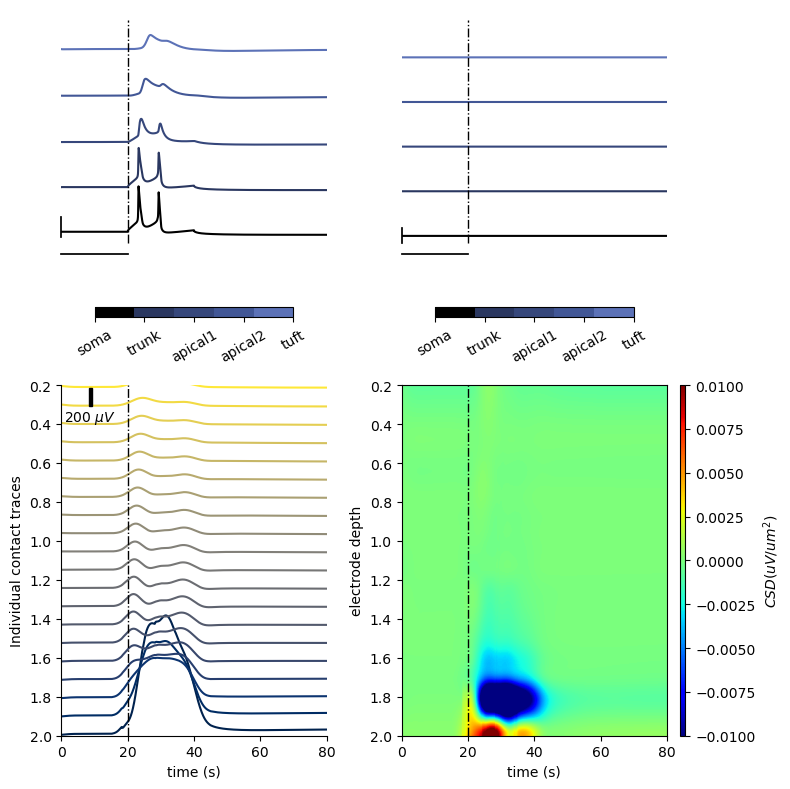

In [9]:
fig, axs = plt.subplots(2,2, figsize=(8,8))

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"]['cell_object'].sections[section].L)

prevL = 0


# find neuron that spikes the most
l5_gids = np.array(net_no_ca.cell_response.spike_gids[0])[np.array(net_no_ca.cell_response.spike_gids[0]) > 170]
l5_spikes, counts = np.unique(l5_gids, return_counts=True)
gid_oi = int(l5_spikes[np.argmax(counts)])

contact_labels, delta = _get_laminar_z_coords(net_no_ca.rec_arrays['probe1'][0].positions)

for i, section in enumerate(sections):

    v = np.array(net_no_ca.cell_response.vsec[0][gid_oi][section])
    axs[0,0].plot(timevec, v + i*110, color=l5_cols_tone[i])
    ca = np.array(net_no_ca.cell_response.ca[0][gid_oi][section])
    axs[0,1].plot(timevec, ca + i*0.0003, color=l5_cols_tone[i])
    prevL += L[i]

cb1 = plt.colorbar(im, ax=axs[0,0],orientation='horizontal',shrink=0.75)
cb2 = plt.colorbar(im, ax=axs[0,1],orientation='horizontal',shrink=0.75)
cb1.ax.set_xticks(np.linspace(0.,np.max(l5cmap.colors),5))
cb2.ax.set_xticks(np.linspace(0.,np.max(l5cmap.colors),5))
cb1.ax.set_xticklabels(['soma','trunk','apical1','apical2','tuft'], rotation=30)
cb2.ax.set_xticklabels(['soma','trunk','apical1','apical2','tuft'], rotation=30)


axs[0,0].spines['top'].set_visible(False)
axs[0,0].spines['right'].set_visible(False)
axs[0,0].plot(np.ones((100,))*20, np.linspace(-100, 450, 100), linewidth=1, color='k', linestyle='-.')
axs[0,1].plot(np.ones((100,))*20, np.linspace(-0, 0.0015, 100), linewidth=1, color='k', linestyle='-.')

axs[0,1].spines['top'].set_visible(False)
axs[0,1].spines['right'].set_visible(False)


new_lim = np.abs(np.round(contact_labels[::2]/1000-2,1))

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,0], show=False, voltage_offset=200)
lfp_ticks = axs[1,0].get_yticks()

axs[1,0].set_ylim((lfp_ticks[0], lfp_ticks[-1]))
axs[1,0].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
axs[1,0].set_yticklabels(new_lim)
axs[1,0].set_xlabel('time (s)')

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,1], show=False, vmin=-0.01, vmax=0.01)
axs[1,1].set_yticks(np.linspace(contact_labels[0], contact_labels[-1], len(new_lim)))
axs[1,1].set_yticklabels(new_lim)

axs[1,0].plot(np.ones((100,))*20, np.linspace(lfp_ticks[0], lfp_ticks[-1], 100), linewidth=1, color='k', linestyle='-.')
axs[1,1].plot(np.ones((100,))*20, np.linspace(contact_labels[0], contact_labels[-1], 100), linewidth=1, color='k', linestyle='-.')

axs[1,0].spines['top'].set_visible(False)
axs[1,0].spines['right'].set_visible(False)


axs[1,0].set_xlim((0, 80))
axs[1,1].set_xlim((0, 80))
axs[0,0].set_xlim((0, 80))
axs[0,1].set_xlim((0, 80))


axs[0,0].spines['left'].set_bounds(-85, -35)
axs[0,0].spines['bottom'].set_bounds(0, 20)
axs[0,1].spines['bottom'].set_bounds(0, 20)
axs[0,0].set_xticks([])
axs[0,1].set_xticks([])
axs[0,0].set_yticks([])
axs[0,1].set_yticks([])
axs[0,1].spines['left'].set_bounds(0, 0.0001)
axs[0,1].spines['bottom'].set_linewidth(1.25)
axs[0,1].spines['left'].set_linewidth(1.25)
axs[0,0].spines['bottom'].set_linewidth(1.25)
axs[0,0].spines['left'].set_linewidth(1.25)
fig.tight_layout()

fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected_block_ca.png'), dpi=300)
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected_block_ca.svg'), dpi=300)
fig.savefig(os.path.join(pathfig,'l5_lfp_csd_connected_block_ca.pdf'), dpi=300)

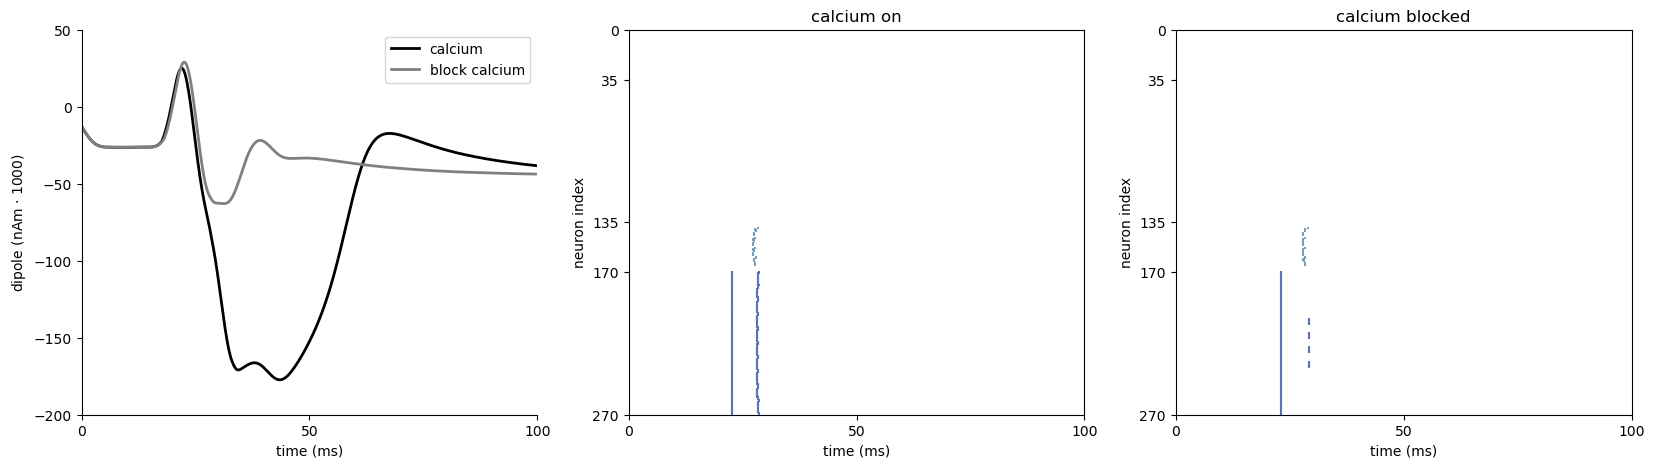

In [10]:
fig, ax = plt.subplots(1,3, figsize=(20,5), sharex=True)
ax[0].plot(timevec, dpl[0].data['L5'], color='k', label='calcium', linewidth=2)
ax[0].plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium', linewidth=2)

ax[0].set_ylabel('dipole (nAm $\cdot$ {scaling_factor})'.format(scaling_factor=scaling_factor))
ax[0].set_xlabel('time (ms)')
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_xlim((0, 100))
ax[0].set_xticks(np.arange(0, 101, 50))
ax[0].set_ylim((-200, 50))
ax[0].set_yticks(np.arange(-200, 51, 50))


I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net, gid) for gid in gids]
ax[1].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[1].set_ylabel('neuron index')
ax[1].set_xlabel('time (ms)')
ax[1].set_ylim([0, 270])
ax[1].set_yticks([0, 35, 135, 170, 270])
ax[1].invert_yaxis()

I = np.array(net_no_ca.cell_response.spike_gids[0]) <270
gids = np.array(net_no_ca.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_no_ca.cell_response.spike_times).reshape(-1,)[I]


colors = [assign_color(net_no_ca, gid) for gid in gids]
ax[2].scatter(times, gids, s=4, alpha=1., c=colors, marker='|')
ax[2].set_ylabel('neuron index')
ax[2].set_xlabel('time (ms)')
ax[2].set_ylim([0, 270])
ax[2].set_yticks([0, 35, 135, 170, 270])
ax[2].invert_yaxis()

ax[1].set_title('calcium on')
ax[2].set_title('calcium blocked')

ax[0].legend()
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_conn.png'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_conn.pdf'))
fig.savefig(os.path.join(pathfig,'dipole_ca_vs_blocked_conn.svg'))

In [24]:
def stim_net(window_len =20, scaling_factor=10, block_ca=True, clear_conn=True, stim='coincidence'):
    net = duecker_ET_model()

    if clear_conn:
        net.clear_connectivity()
    
    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    if block_ca:
        net = net_block_ca(net)


    if stim == 'coincidence':
        net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_prox',amplitude=3,t0=t0,tstop=t0+3)
        net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_dist',amplitude=0.3,t0=t0+3,tstop=t0+6)
    elif stim == 'distal':
        net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_dist',amplitude=1.5,t0=t0,tstop=t0+3)
    elif stim == 'one_spike':
        net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_prox',amplitude=3,t0=t0,tstop=t0+3)

    dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
    dpl[0].smooth(window_len).scale(scaling_factor)

    return net, dpl


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 

AttributeError: 'Network' object has no attribute 'plot_spikes_raster'

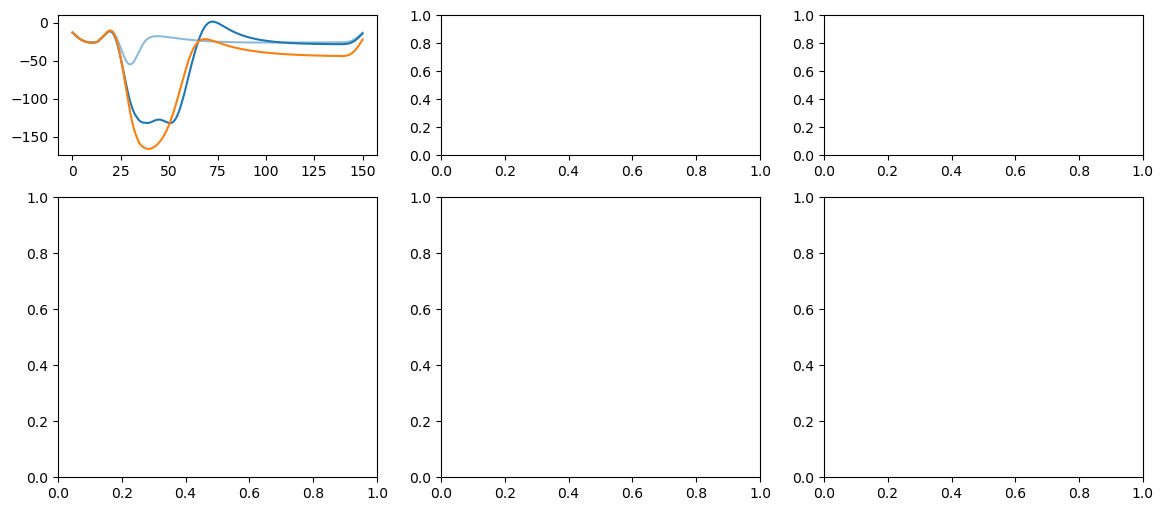

In [25]:

fig, ax = plt.subplots(2,3, figsize=(14,6), height_ratios=[0.5,1])

window_len, scaling_factor = 20, 1000


# dipole coincidence detection

_, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=True, stim='coincidence')

# no conn dipole
ax[0,0].plot(timevec, dpl[0].data['L5'], color='tab:blue')

_, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=True, stim='coincidence')

ax[0,0].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:blue', alpha=0.5)

# conn dipole
net, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=False, stim='coincidence')
ax[0,0].plot(timevec, dpl[0].data['L5'], color='tab:orange')
#net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=ax[1,0], show=False, vmin=-0.001, vmax=0.001)
net.plot_spikes_raster(ax=ax[1,0], show=False)

net_no_ca, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=False, stim='coincidence')
ax[0,0].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:orange', alpha=0.5)

# dipole distal drive
_, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=True, stim='distal')
ax[0,1].plot(timevec, dpl[0].data['L5'], color='tab:blue')
_, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=True, stim='distal')
ax[0,1].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:blue', alpha=0.5)
net, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=False, stim='distal')
net.plot_spikes_raster(ax=ax[1,1], show=False)

#net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=ax[1,1], show=False, vmin=-0.001, vmax=0.001)

ax[0,1].plot(timevec, dpl[0].data['L5'], color='tab:orange')
net_no_ca, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=False, stim='distal')
ax[0,1].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:orange', alpha=0.5)


# one spike
_, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=True, stim='one_spike')
ax[0,2].plot(timevec, dpl[0].data['L5'], color='tab:blue', label='unconn')
_, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=True, stim='one_spike')
ax[0,2].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:blue', label='unconn block ca', alpha=0.5)
net, dpl = stim_net(window_len, scaling_factor, block_ca=False, clear_conn=False, stim='one_spike')
net.plot_spikes_raster(ax=ax[1,2], show=False)

#net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=ax[1,2], show=False, vmin=-0.001, vmax=0.001)

ax[0,2].plot(timevec, dpl[0].data['L5'], color='tab:orange', label='conn')
net_no_ca, dpl_no_ca = stim_net(window_len, scaling_factor, block_ca=True, clear_conn=False, stim='one_spike')
ax[0,2].plot(timevec, dpl_no_ca[0].data['L5'], color='tab:orange', label='conn block ca', alpha=0.5)


ax[0,0].set_title('coincident inputs')
ax[0,1].set_title('distal drive')
ax[0,2].set_title('one spike')
ax[0,0].set_ylabel('dipole (nAm x 1000)')
ax[0,0].set_xlabel('time (s)')
ax[0,0].set_xlabel('time (s)')

ax[0,2].legend()
# fig.savefig(os.path.join(pathfig,'dipole_beta_events.svg'))

In [ ]:
fig, axs = plt.subplots(2,3, figsize=(8,6), width_ratios=[0.2, 1, 1])

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net_no_ca.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net_no_ca.cell_response.vsec[0][171][section])
    axs[0,1].plot(timevec, v + i*110)
    ca = np.array(net_no_ca.cell_response.ca[0][171][section])
    axs[0,2].plot(timevec, ca + i*0.0003)
    prevL += L[i]


axs[0,0].set_xticks([])
axs[1,0].set_xticks([])
axs[0,1].set_title('membrane potential')
axs[0,2].set_title('calcium concentration')

new_lim = contact_labels[0:len(contact_labels):2]


net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,1], show=False)
lfp_ticks = axs[1,1].get_yticks()
lfp_ticks = lfp_ticks[0:-1:2]

axs[1,0].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_yticks(lfp_ticks)
axs[1,1].set_ylim((lfp_ticks[0], lfp_ticks[-1]+50))
axs[1,1].set_xlabel('time (s)')
axs[1,1].set_title('LFP')

net_no_ca.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,2], show=False, vmin=-0.001, vmax=0.001)
#axs[1,2].set_yticks(new_ticks)
axs[1,2].set_title('CSD')
axs[1,2].set_ylim((-100, 2300))
axs[1,0].set_ylim(axs[1,2].get_ylim())
axs[0,0].set_ylim(axs[1,2].get_ylim())

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'connected','l5_lfp_csd_no_ca.png'))
#fig.savefig(os.path.join(pathfig,'l5_lfp_csd_no_ca.svg'))


In [ ]:
# refractory period

imfig = plt.imshow(np.array([np.arange(50, 450, 50)]), cmap=cm_time_map)
plt.close()

fig, ax = plt.subplots(3,1, figsize=(10,6), height_ratios=[0.5,1,0.1])

window_len, scaling_factor = 20, 1000


prox1_weights_ampa = {'L2_basket': 0.,
                        'L2_pyramidal': 0,
                        'L5_basket': 0,
                        'L5_pyramidal': 1}
prox1_weights_nmda = {'L2_basket': 0.,
                        'L2_pyramidal': 0.,
                        'L5_basket': 0.,
                        'L5_pyramidal': 1}


for i,time_diff in enumerate(np.arange(50, 450, 50)):
    net = duecker_ET_model()
    net.clear_connectivity()

    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

    net.add_evoked_drive('evprox1',
                            mu=20.,
                            sigma=1,
                            numspikes=1,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)


    net.add_evoked_drive('evprox2',
                            mu=20.+time_diff,
                            sigma=1,
                            numspikes=1,
                            location='proximal',
                            weights_ampa=prox1_weights_ampa,
                            weights_nmda=prox1_weights_nmda,
                            synaptic_delays=synaptic_delays_p, event_seed=544)


    
    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=550, n_trials=1, bsl_cor='calcium')
    smooth_dpl = dpl[0].copy()
    smooth_dpl.smooth(window_len).scale(scaling_factor)

    if i == 0:
        net.cell_response.plot_spikes_hist(ax = ax[0], show=False, color='r')

    ax[1].plot(smooth_dpl.times, smooth_dpl.data['L5'], label='%.1f ms' % time_diff, color = cm_time[i])

ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('dipole (nAm x {scaling_factor})'.format(scaling_factor=scaling_factor))

ax[2].set_axis_off()
cb = fig.colorbar(imfig, ax=ax[2], orientation="horizontal", fraction=.5)
cb.set_label("x")
cb.set_ticks(np.arange(50, 400, 100))

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'refractory_proximal.pdf'))


In [ ]:
np.arange(50, 450, 50)

In [ ]:
imfig = plt.imshow(np.array([np.arange(50, 400, 50)]), cmap=cm_time_map)
plt.close()

fig, ax = plt.subplots(3,1, figsize=(12,6), height_ratios=[0.5,1,0.1])
ax[2].set_axis_off()
cb = fig.colorbar(imfig, ax=ax[2], orientation="horizontal", fraction=.5)
cb.set_label("x")
cb.set_ticks(np.arange(50, 400, 100))



In [ ]:
fig.savefig(os.path.join(pathfig,'refractory_proximal.pdf'))


In [ ]:
# distal drive 
net = duecker_ET_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2400,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 1.5
t0 = 30

net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl[0].smooth(window_len).scale(scaling_factor)


net_no_ca = duecker_ET_model()
net_no_ca.clear_connectivity()

# block Ca
# 
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in sections:
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_HVA']['gbar_Ca_HVA'][1])

net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_HVA'] = 0


net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0,tstop=t0+3)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


fig, ax = plt.subplots()
ax.plot(timevec, dpl[0].data['L5'], color='k', label='calcium')
ax.plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5],label='block calcium')

ax.set_title('smoothed dipole')
ax.set_ylabel('dipole (nAm x 3000)')
ax.set_xlabel('time (s)')
fig.legend()
fig.savefig(os.path.join(pathfig,'connected','dipole_distal_drive.png'))


In [ ]:
# refractory period?
# Sarah used a proximal drive, so this is not exactly comparable

window_len, scaling_factor = 20, 3000

fig, ax = plt.subplots()

ampl = 1.5
t0 = 20

second_drive_times = np.arange(50, 200, 20)


for dt in second_drive_times:

    net = duecker_ET_model()
    net.clear_connectivity()

    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='soma_1',amplitude=3,t0=t0+3,tstop=t0+3+3)
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='soma_2',amplitude=3,t0=t0+dt+3,tstop=t0+dt+3+3)

    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='distal_1',amplitude=1,t0=t0+3,tstop=t0+3+3)
    net.add_tonic_bias(cell_type='L5_pyramidal',section='apical_tuft',bias_name='distal_2',amplitude=1,t0=t0+dt+3,tstop=t0+dt+3+3)

    dpl = simulate_dipole(net, tstop=240, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')
    dpl[0].smooth(window_len).scale(scaling_factor)

    ax.plot(dpl[0].times, dpl[0].data['L5'], label='second drive at '+str(dt)+' ms')

fig.legend()

fig.savefig(os.path.join(pathfig,'connected','dipole_refractory.png'))


In [ ]:
fig, axs = plt.subplots(1,4, figsize=(12,4))

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[1].plot(timevec, v + i*110)
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[2].plot(timevec, ca + i*0.0003)
    prevL += L[i]

axs[3].plot(timevec, dpl[0].data['agg'])

fig.tight_layout()